# **Exp 12 – Random Forest on Selected Feature Dataset | Extended Log Transformations**

1. Prepare the selected feature dataset by separating features and target, excluding customer ID. Replace infinite values with NaN.
2. Split the data into 64% training, 16% validation, and 20% testing using stratification.
3. Identify numerical and categorical features for preprocessing.
4. Apply extended log transformations to selected numerical features:
   - log1p(x) for positive or zero-valued features.
   - sign(x) × log1p(|x|) for features containing negative values.
5. Validate that features selected for log1p do not contain negative values.
6. Apply feature-specific outlier capping:
   - Two-sided capping (1st–99th percentile) for selected features.
   - Upper-only capping (99th percentile) for selected right-skewed features.
7. Calculate outlier limits using training data only and apply the same limits to validation and test data.
8. Compare feature skewness before and after log transformations to evaluate skewness reduction.
9. Impute numerical missing values using the median. Impute categorical missing values using the most frequent value and apply One-Hot Encoding (OHE).
10. Train a Random Forest Classifier with 500 trees and class_weight='balanced' to handle class imbalance.
11. Generate validation probabilities and plot the Precision-Recall curve.
12. Perform threshold analysis (0.05–0.55, with 0.01 intervals) and select the threshold with the highest validation F1 Score.
13. Apply the selected threshold to training, validation, and test probabilities to generate:
    0 = Retained | 1 = Churned.
14. Evaluate model performance using Accuracy, Precision, Recall, F1 Score, ROC-AUC, PR-AUC, confusion matrix, and classification report.
15. Analyse and visualize the top 20 feature importances.
16. Display the selected threshold, final test performance, input feature count, and number of log-transformed features.

**Experiment objective:**

Evaluate Random Forest performance on a selected feature dataset using more extensive log transformations to reduce feature skewness, while retaining feature-specific outlier capping and class imbalance handling.

## 0. IMPORT LIBRARIES

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, precision_recall_curve,
    confusion_matrix, classification_report
)

In [2]:
df = pd.read_csv('../data_for_predictions.csv')
df.drop(columns=["Unnamed: 0"], inplace=True)
df.head()

,id,cons_12m,cons_gas_12m,cons_last_month,forecast_cons_12m,forecast_discount_energy,forecast_meter_rent_12m,forecast_price_energy_off_peak,forecast_price_energy_peak,forecast_price_pow_off_peak,...,months_modif_prod,months_renewal,channel_MISSING,channel_ewpakwlliwisiwduibdlfmalxowmwpci,channel_foosdfpfkusacimwkcsosbicdxkicaua,channel_lmkebamcaaclubfxadlmueccxoimlema,channel_usilxuppasemubllopkaafesmlibmsdf,origin_up_kamkkxfxxuwbdslkwifmmcsiusiuosws,origin_up_ldkssxwpmemidmecebumciepifcamkci,origin_up_lxidpiddsbxsbosboudacockeimpuepw
0,24011ae4ebbe3035111d65fa7c15bc57,0.000000,4.739944,0.000000,0.000000,0.0,0.444045,0.114481,0.098142,40.606701,...,2,6,0,0,1,0,0,0,0,1
1,d29c2c54acc38ff3c0614d0a653813dd,3.668479,0.000000,0.000000,2.280920,0.0,1.237292,0.145711,0.000000,44.311378,...,76,4,1,0,0,0,0,1,0,0
2,764c75f661154dac3a6c254cd082ea7d,2.736397,0.000000,0.000000,1.689841,0.0,1.599009,0.165794,0.087899,44.311378,...,68,8,0,0,1,0,0,1,0,0
3,bba03439a292a1e166f80264c16191cb,3.200029,0.000000,0.000000,2.382089,0.0,1.318689,0.146694,0.000000,44.311378,...,69,9,0,0,0,1,0,1,0,0
4,149d57cf92fc41cf94415803a877cb4b,3.646011,0.000000,2.721811,2.650065,0.0,2.122969,0.116900,0.100015,40.606701,...,71,9,1,0,0,0,0,1,0,0


## 1. CONFIGURATION

In [3]:
EXPERIMENT_NAME = "Exp 12 – Random Forest on Selected Feature Dataset | Extended Log Transformations"
RANDOM_STATE = 42

# Positive / zero features: log1p(x)
log1p_features = [
    "margin_per_consumption",
    "forecast_cons_ratio",
    "tenure_margin_interaction",
    "customer_value_proxy",
    "var_6m_price_off_peak_fix",
    "var_6m_price_off_peak",
    "var_year_price_off_peak_fix",
    "var_year_price_off_peak",
    "var_6m_price_off_peak_var",
    "discount_consumption_interaction",
    "off_peak_fix_cv",
    "off_peak_var_cv",
    "var_year_price_off_peak_var",
    "var_6m_price_peak",
    "var_6m_price_peak_fix",
    "cons_gas_12m",
    "var_6m_price_mid_peak_fix",
    "var_6m_price_mid_peak",
    "var_6m_price_mid_peak_var",
    "mid_peak_var_cv",
    "peak_fix_cv",
    "mid_peak_fix_cv",
    "var_year_price_peak_var",
    "var_6m_price_peak_var",
    "forecast_cons_12m",
    "var_year_price_mid_peak_var",
    "var_year_price_peak",
    "var_year_price_peak_fix",
    "var_year_price_mid_peak",
    "var_year_price_mid_peak_fix",
    "margin_per_power",
    "cons_last_month",
    "product_adoption_rate",
    "consumption_per_power",
    "margin_net_pow_ele",
    "cons_12m",
    "gas_product_interaction",
    "peak_var_cv",
    "pow_max",
    "forecast_year_ratio",
    "gas_consumption_share",
    "forecast_cons_year",
    "cons_last_month_ratio",
    "imp_cons",
    "peak_mid_peak_fix_mean_diff",
    "margin_per_product",
    "net_margin",
    "forecast_meter_rent_12m",
    "months_activ",
    "peak_mid_peak_var_mean_diff"
]

# Features containing negative values: sign(x) * log(1 + abs(x))
signed_log1p_features = [
    "dec_jan_mid_peak_fix_diff",
    "dec_jan_off_peak_fix_diff",
    "cons_last_month_diff",
    "price_consumption_exposure",
    "dec_jan_mid_peak_var_diff",
    "forecast_cons_diff",
    "price_power_interaction",
    "peak_6m_change"
]

## 2. PREPARE SELECTED DATASET

In [4]:
df_selected = df.copy()

if 'churn' not in df_selected.columns:
    raise ValueError("The selected dataframe must contain a 'churn' column.")

X = df_selected.drop(columns=['id', 'churn'], errors='ignore').copy()
y = df_selected['churn'].astype(int).copy()
X = X.replace([np.inf, -np.inf], np.nan)

print("=" * 75)
print(EXPERIMENT_NAME)
print("=" * 75)
print("Selected Dataset Shape:", df_selected.shape)
print("Feature Matrix Shape:", X.shape)
print("Total Missing Values:", int(X.isna().sum().sum()))
print("\nTarget Distribution:")
print(y.value_counts().sort_index())
print("\nTarget Percentage:")
print((y.value_counts(normalize=True).sort_index() * 100).round(2))

Exp 12 – Random Forest on Selected Feature Dataset | Extended Log Transformations
Selected Dataset Shape: (14606, 63)
Feature Matrix Shape: (14606, 61)
Total Missing Values: 0

Target Distribution:
churn
0    13187
1     1419
Name: count, dtype: int64

Target Percentage:
churn
0    90.28
1     9.72
Name: proportion, dtype: float64


## 3. TRAIN / VALIDATION / TEST SPLITS

In [5]:
# 64% training, 16% validation, 20% test
X_train_full, X_test, y_train_full, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)

X_model_train, X_val, y_model_train, y_val = train_test_split(
    X_train_full, y_train_full, test_size=0.20,
    random_state=RANDOM_STATE, stratify=y_train_full
)

print("\n==== SPLIT SIZES ====")
print("Model Training:", X_model_train.shape)
print("Validation:", X_val.shape)
print("Test:", X_test.shape)


==== SPLIT SIZES ====
Model Training: (9347, 61)
Validation: (2337, 61)
Test: (2922, 61)


## 4. IDENTIFY FEATURE TYPES

In [6]:
categorical_cols = X.select_dtypes(
    include=['object', 'category', 'bool']
).columns.tolist()

numerical_cols = X.select_dtypes(include=np.number).columns.tolist()

log1p_features = [
    col for col in log1p_features if col in numerical_cols
]
signed_log1p_features = [
    col for col in signed_log1p_features if col in numerical_cols
]

overlapping_features = set(log1p_features).intersection(signed_log1p_features)
if overlapping_features:
    raise ValueError(f"Features appear in both log lists: {overlapping_features}")

print("\nNumber of Numerical Features:", len(numerical_cols))
print("Categorical Features:", categorical_cols)
print("\nAvailable log1p Features:", log1p_features)
print("\nAvailable Signed-log Features:", signed_log1p_features)


Number of Numerical Features: 61
Categorical Features: []

Available log1p Features: ['var_6m_price_off_peak_fix', 'var_6m_price_off_peak', 'var_year_price_off_peak_fix', 'var_year_price_off_peak', 'var_6m_price_off_peak_var', 'var_year_price_off_peak_var', 'var_6m_price_peak', 'var_6m_price_peak_fix', 'cons_gas_12m', 'var_6m_price_mid_peak_fix', 'var_6m_price_mid_peak', 'var_6m_price_mid_peak_var', 'var_year_price_peak_var', 'var_6m_price_peak_var', 'forecast_cons_12m', 'var_year_price_mid_peak_var', 'var_year_price_peak', 'var_year_price_peak_fix', 'var_year_price_mid_peak', 'var_year_price_mid_peak_fix', 'cons_last_month', 'margin_net_pow_ele', 'cons_12m', 'pow_max', 'imp_cons', 'peak_mid_peak_fix_mean_diff', 'net_margin', 'forecast_meter_rent_12m', 'months_activ', 'peak_mid_peak_var_mean_diff']

Available Signed-log Features: []


## 5. OUTLIER CAPPING CONFIGURATION

In [7]:
two_sided_features = [
    "cons_last_month_diff",
    "forecast_cons_diff",
    "price_consumption_exposure"
]

upper_only_features = [
    "consumption_per_power",
    "cons_12m",
    "cons_last_month",
    "pow_max",
    "forecast_cons_year",
    "imp_cons",
    "net_margin",
    "margin_per_product"
]

two_sided_features = [
    col for col in two_sided_features if col in numerical_cols
]
upper_only_features = [
    col for col in upper_only_features if col in numerical_cols
]

## 6. CALCULATE OUTLIER LIMITS USING TRAINING DATA ONLY

In [8]:
cap_limits = {}

for col in two_sided_features:
    cap_limits[col] = {
        'lower': X_model_train[col].quantile(0.01),
        'upper': X_model_train[col].quantile(0.99)
    }

for col in upper_only_features:
    cap_limits[col] = {
        'lower': None,
        'upper': X_model_train[col].quantile(0.99)
    }

def apply_capping(data, limits):
    data_out = data.copy()
    for col, bounds in limits.items():
        if bounds['lower'] is not None:
            data_out[col] = data_out[col].clip(lower=bounds['lower'])
        if bounds['upper'] is not None:
            data_out[col] = data_out[col].clip(upper=bounds['upper'])
    return data_out

X_model_train_capped = apply_capping(X_model_train, cap_limits)
X_val_capped = apply_capping(X_val, cap_limits)
X_test_capped = apply_capping(X_test, cap_limits)

## 7. OUTLIER CAPPING SUMMARY

In [9]:
cap_summary = []

for col, bounds in cap_limits.items():
    cap_summary.append({
        'Feature': col,
        'Original Min': X_model_train[col].min(),
        'Capped Min': X_model_train_capped[col].min(),
        'Original Max': X_model_train[col].max(),
        'Capped Max': X_model_train_capped[col].max(),
        'Lower Limit': bounds['lower'],
        'Upper Limit': bounds['upper']
    })

cap_summary_df = pd.DataFrame(cap_summary)

print("\n==== OUTLIER CAPPING SUMMARY ====")
if not cap_summary_df.empty:
    print(cap_summary_df.round(3).to_string(index=False))
else:
    print("No configured outlier features were found.")


==== OUTLIER CAPPING SUMMARY ====
        Feature  Original Min  Capped Min  Original Max  Capped Max Lower Limit  Upper Limit
       cons_12m           0.0         0.0         6.793       6.494        None        6.494
cons_last_month           0.0         0.0         5.887       5.583        None        5.583
        pow_max           3.3         3.3       320.000      77.108        None       77.108
       imp_cons           0.0         0.0         4.177       3.089        None        3.089
     net_margin           0.0         0.0     24570.650     881.513        None      881.513


## 8. APPLY LOG TRANSFORMATIONS

In [10]:
def signed_log1p(series):
    return np.sign(series) * np.log1p(np.abs(series))

def apply_log_transformations(data):
    data_out = data.copy()
    for col in log1p_features:
        data_out[col] = np.log1p(data_out[col])
    for col in signed_log1p_features:
        data_out[col] = signed_log1p(data_out[col])
    return data_out

# Validate log1p domain across all splits after capping.
for split_name, split_data in [
    ('Training', X_model_train_capped),
    ('Validation', X_val_capped),
    ('Test', X_test_capped)
]:
    invalid_features = [
        col for col in log1p_features
        if (split_data[col].dropna() < 0).any()
    ]
    if invalid_features:
        raise ValueError(
            f"Negative values found in log1p features in {split_name}: "
            f"{invalid_features}. Review their transformations."
        )

X_model_train_transformed = apply_log_transformations(X_model_train_capped)
X_val_transformed = apply_log_transformations(X_val_capped)
X_test_transformed = apply_log_transformations(X_test_capped)

print("\nLog Transformations Applied Successfully.")
print("Total Log-transformed Features:",
      len(log1p_features) + len(signed_log1p_features))


Log Transformations Applied Successfully.
Total Log-transformed Features: 30


## 9. SKEWNESS COMPARISON

In [11]:
skewness_rows = []

for col in log1p_features:
    before = X_model_train_capped[col].dropna()
    after = X_model_train_transformed[col].dropna()
    skew_before = before.skew()
    skew_after = after.skew()

    skewness_rows.append({
        'Feature': col,
        'Transformation': 'log1p(x)',
        'Skew_Before': skew_before,
        'Skew_After': skew_after,
        'Absolute_Skew_Reduction': abs(skew_before) - abs(skew_after)
    })

for col in signed_log1p_features:
    before = X_model_train_capped[col].dropna()
    after = X_model_train_transformed[col].dropna()
    skew_before = before.skew()
    skew_after = after.skew()

    skewness_rows.append({
        'Feature': col,
        'Transformation': 'signed_log1p(x)',
        'Skew_Before': skew_before,
        'Skew_After': skew_after,
        'Absolute_Skew_Reduction': abs(skew_before) - abs(skew_after)
    })

skewness_comparison_df = pd.DataFrame(skewness_rows)

print("\n==== SKEWNESS COMPARISON ====")
if not skewness_comparison_df.empty:
    skewness_comparison_df = skewness_comparison_df.sort_values(
        'Absolute_Skew_Reduction', ascending=False
    )
    print(skewness_comparison_df.round(4).to_string(index=False))
else:
    print("No selected log-transformation features were available.")


==== SKEWNESS COMPARISON ====
                    Feature Transformation  Skew_Before  Skew_After  Absolute_Skew_Reduction
    var_year_price_off_peak       log1p(x)      21.2350      9.6549                  11.5801
var_year_price_off_peak_fix       log1p(x)      21.2351      9.6554                  11.5797
      var_6m_price_off_peak       log1p(x)      22.3314     12.8848                   9.4466
  var_6m_price_off_peak_fix       log1p(x)      22.3315     12.8853                   9.4461
         margin_net_pow_ele       log1p(x)       4.6736     -1.3159                   3.3577
        var_year_price_peak       log1p(x)       7.6252      5.4071                   2.2181
    var_year_price_peak_fix       log1p(x)       7.6252      5.4071                   2.2181
          var_6m_price_peak       log1p(x)      10.9512      8.8139                   2.1373
      var_6m_price_peak_fix       log1p(x)      10.9512      8.8139                   2.1373
    var_year_price_mid_peak       log1p

## 10. PREPROCESSING PIPELINE

In [12]:
numerical_pipeline = Pipeline(steps=[
    ('imputer', SimpleImputer(
        strategy='median',
        keep_empty_features=True
    ))
])

categorical_pipeline = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor = ColumnTransformer(
    transformers=[
        ('numeric', numerical_pipeline, numerical_cols),
        ('categorical', categorical_pipeline, categorical_cols)
    ],
    remainder='drop',
    verbose_feature_names_out=False
)

## 11. RANDOM FOREST MODEL

In [13]:
rf_model = RandomForestClassifier(
    n_estimators=500,
    max_depth=None,
    min_samples_split=5,
    min_samples_leaf=5,
    max_features=0.5,
    class_weight='balanced',
    random_state=RANDOM_STATE,
    n_jobs=-1
)

rf_pipeline = Pipeline(steps=[
    ('preprocessing', preprocessor),
    ('model', rf_model)
])

## 12. FIT MODEL

In [14]:
rf_pipeline.fit(X_model_train_transformed, y_model_train)
print("\nRandom Forest Model Fitted Successfully.")


Random Forest Model Fitted Successfully.


## 13. VALIDATION PROBABILITIES AND PR CURVE

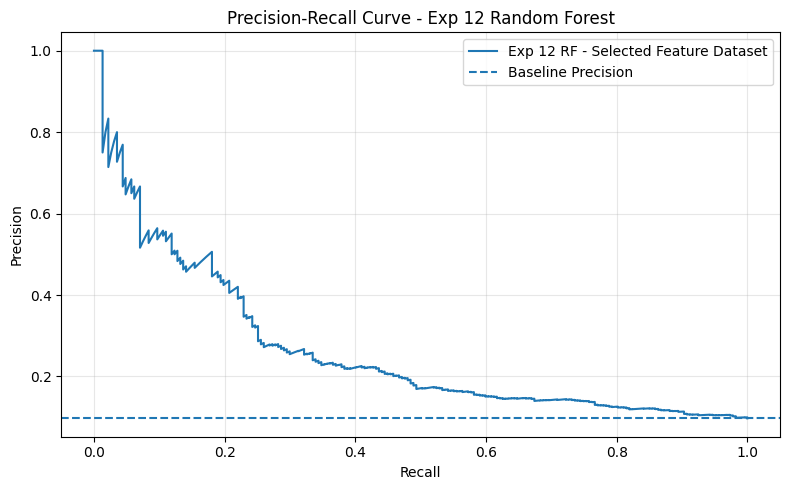

In [15]:
y_prob_val = rf_pipeline.predict_proba(X_val_transformed)[:, 1]

precision_curve, recall_curve, _ = precision_recall_curve(
    y_val, y_prob_val
)

plt.figure(figsize=(8, 5))
plt.plot(
    recall_curve, precision_curve,
    label='Exp 12 RF - Selected Feature Dataset'
)
plt.axhline(
    y=y_val.mean(),
    linestyle='--',
    label='Baseline Precision'
)
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve - Exp 12 Random Forest')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 14. VALIDATION THRESHOLD ANALYSIS


==== THRESHOLD ANALYSIS ====
 Threshold  Precision  Recall  F1 Score
      0.05     0.1030  0.9780    0.1864
      0.06     0.1054  0.9736    0.1903
      0.07     0.1055  0.9427    0.1898
      0.08     0.1063  0.9119    0.1904
      0.09     0.1103  0.9031    0.1965
      0.10     0.1148  0.8855    0.2032
      0.11     0.1182  0.8634    0.2080
      0.12     0.1198  0.8194    0.2091
      0.13     0.1241  0.8018    0.2150
      0.14     0.1291  0.7709    0.2211
      0.15     0.1379  0.7577    0.2334
      0.16     0.1432  0.7269    0.2393
      0.17     0.1443  0.6740    0.2378
      0.18     0.1452  0.6256    0.2357
      0.19     0.1509  0.5991    0.2411
      0.20     0.1602  0.5815    0.2512
      0.21     0.1651  0.5507    0.2541
      0.22     0.1707  0.5286    0.2581
      0.23     0.1710  0.4934    0.2540
      0.24     0.1849  0.4846    0.2676
      0.25     0.1981  0.4670    0.2782
      0.26     0.2063  0.4581    0.2845
      0.27     0.2190  0.4361    0.2916
      0.28

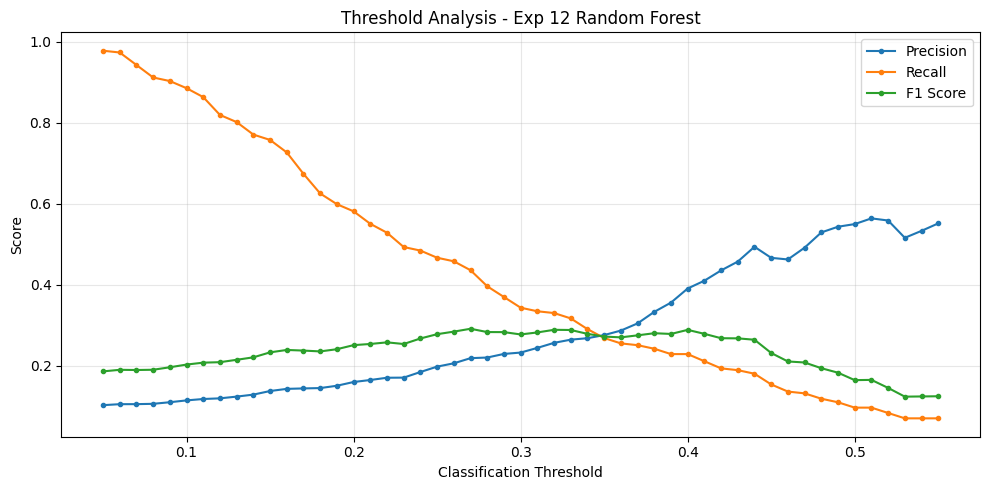

In [16]:
threshold_values = np.arange(0.05, 0.56, 0.01)
threshold_rows = []

for threshold in threshold_values:
    y_pred = (y_prob_val >= threshold).astype(int)
    threshold_rows.append({
        'Threshold': threshold,
        'Precision': precision_score(y_val, y_pred, zero_division=0),
        'Recall': recall_score(y_val, y_pred, zero_division=0),
        'F1 Score': f1_score(y_val, y_pred, zero_division=0)
    })

threshold_df = pd.DataFrame(threshold_rows)
best_threshold_row = threshold_df.loc[threshold_df['F1 Score'].idxmax()]
best_threshold = float(best_threshold_row['Threshold'])

print("\n==== THRESHOLD ANALYSIS ====")
print(threshold_df.round(4).to_string(index=False))
print("\n==== BEST VALIDATION THRESHOLD ====")
print(best_threshold_row)

plt.figure(figsize=(10, 5))
plt.plot(
    threshold_df['Threshold'], threshold_df['Precision'],
    marker='o', markersize=3, label='Precision'
)
plt.plot(
    threshold_df['Threshold'], threshold_df['Recall'],
    marker='o', markersize=3, label='Recall'
)
plt.plot(
    threshold_df['Threshold'], threshold_df['F1 Score'],
    marker='o', markersize=3, label='F1 Score'
)
plt.xlabel('Classification Threshold')
plt.ylabel('Score')
plt.title('Threshold Analysis - Exp 12 Random Forest')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 15. TRAIN / VALIDATION / TEST PREDICTIONS

In [17]:
y_prob_train = rf_pipeline.predict_proba(X_model_train_transformed)[:, 1]
y_prob_test = rf_pipeline.predict_proba(X_test_transformed)[:, 1]

y_pred_train = (y_prob_train >= best_threshold).astype(int)
y_pred_val = (y_prob_val >= best_threshold).astype(int)
y_pred_test = (y_prob_test >= best_threshold).astype(int)

## 16. EVALUATION FUNCTION

In [18]:
def calculate_metrics(y_true, y_pred, y_prob):
    return {
        'Accuracy': accuracy_score(y_true, y_pred),
        'Precision': precision_score(y_true, y_pred, zero_division=0),
        'Recall': recall_score(y_true, y_pred, zero_division=0),
        'F1 Score': f1_score(y_true, y_pred, zero_division=0),
        'ROC-AUC': roc_auc_score(y_true, y_prob),
        'PR-AUC': average_precision_score(y_true, y_prob)
    }

train_metrics = calculate_metrics(
    y_model_train, y_pred_train, y_prob_train
)
validation_metrics = calculate_metrics(
    y_val, y_pred_val, y_prob_val
)
test_metrics = calculate_metrics(
    y_test, y_pred_test, y_prob_test
)

def print_metrics(title, metrics):
    print(f"\n==== {title} ====")
    for metric, value in metrics.items():
        print(f"{metric:12}: {value:.4f}")

print_metrics('TRAIN METRICS', train_metrics)
print_metrics('VALIDATION METRICS', validation_metrics)
print_metrics('TEST METRICS', test_metrics)


==== TRAIN METRICS ====
Accuracy    : 0.9386
Precision   : 0.6127
Recall      : 1.0000
F1 Score    : 0.7598
ROC-AUC     : 0.9998
PR-AUC      : 0.9974

==== VALIDATION METRICS ====
Accuracy    : 0.7942
Precision   : 0.2190
Recall      : 0.4361
F1 Score    : 0.2916
ROC-AUC     : 0.6834
PR-AUC      : 0.2654

==== TEST METRICS ====
Accuracy    : 0.7971
Precision   : 0.2332
Recall      : 0.4754
F1 Score    : 0.3129
ROC-AUC     : 0.6927
PR-AUC      : 0.3088


## 17. TEST CONFUSION MATRIX

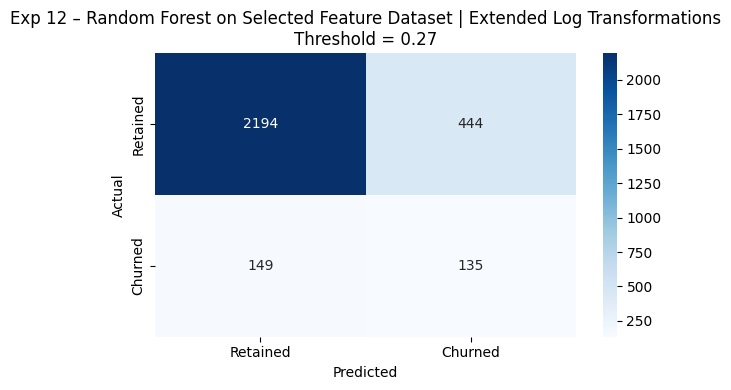

In [19]:
cm = confusion_matrix(y_test, y_pred_test)

plt.figure(figsize=(6, 4))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Retained', 'Churned'],
    yticklabels=['Retained', 'Churned']
)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title(
    f'{EXPERIMENT_NAME}\nThreshold = {best_threshold:.2f}'
)
plt.tight_layout()
plt.show()

## 18. TEST CLASSIFICATION REPORT

In [20]:
print("\n==== TEST CLASSIFICATION REPORT ====")
print(classification_report(
    y_test,
    y_pred_test,
    target_names=['Retained', 'Churned'],
    zero_division=0
))


==== TEST CLASSIFICATION REPORT ====
              precision    recall  f1-score   support

    Retained       0.94      0.83      0.88      2638
     Churned       0.23      0.48      0.31       284

    accuracy                           0.80      2922
   macro avg       0.58      0.65      0.60      2922
weighted avg       0.87      0.80      0.83      2922



## 19. FEATURE IMPORTANCE

In [21]:
rf_fitted = rf_pipeline.named_steps['model']
feature_names = rf_pipeline.named_steps['preprocessing'].get_feature_names_out()

feature_importance_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': rf_fitted.feature_importances_
}).sort_values(
    by='Importance', ascending=False
).reset_index(drop=True)

print("\n==== TOP 20 FEATURE IMPORTANCES ====")
print(feature_importance_df.head(20).round(5).to_string(index=False))


==== TOP 20 FEATURE IMPORTANCES ====
                        Feature  Importance
                       cons_12m     0.06359
        forecast_meter_rent_12m     0.06317
             margin_net_pow_ele     0.05829
           margin_gross_pow_ele     0.05121
              forecast_cons_12m     0.04553
                     net_margin     0.04552
                cons_last_month     0.04190
                   months_activ     0.03841
                        pow_max     0.03733
              months_modif_prod     0.03646
    var_year_price_off_peak_var     0.03195
        var_year_price_off_peak     0.02979
                       imp_cons     0.02935
    off_peak_peak_var_mean_diff     0.02921
offpeak_diff_dec_january_energy     0.02788
off_peak_mid_peak_var_mean_diff     0.02592
 forecast_price_energy_off_peak     0.01770
                  months_to_end     0.01697
      var_6m_price_off_peak_var     0.01687
          var_6m_price_off_peak     0.01641


## 20. FEATURE IMPORTANCE VISUALIZATION

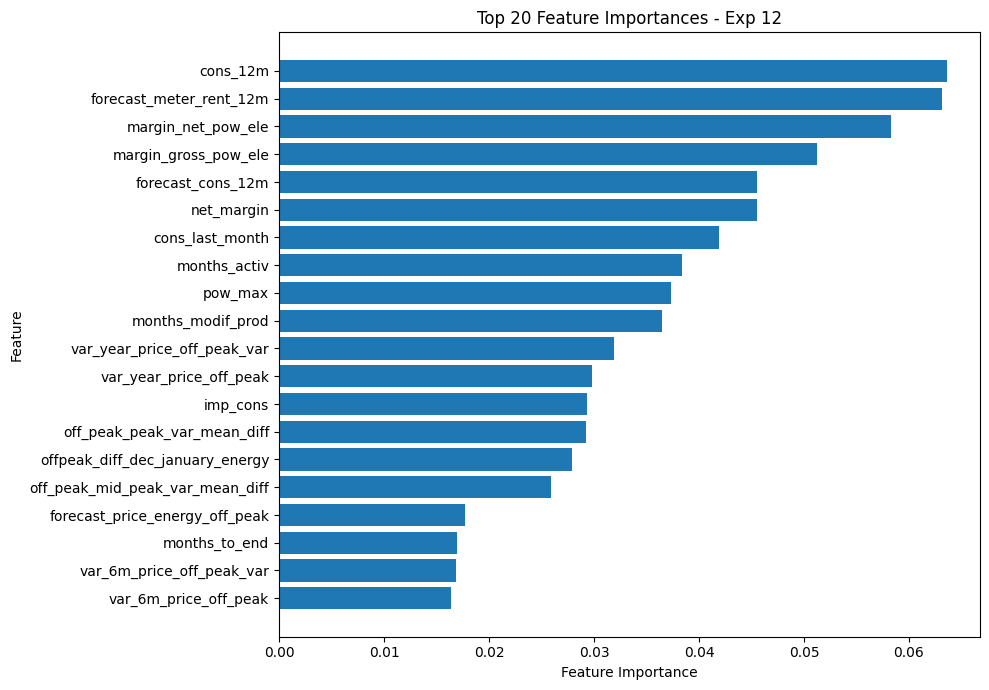

In [22]:
top_features = feature_importance_df.head(20).sort_values(
    'Importance', ascending=True
)

plt.figure(figsize=(10, 7))
plt.barh(top_features['Feature'], top_features['Importance'])
plt.xlabel('Feature Importance')
plt.ylabel('Feature')
plt.title('Top 20 Feature Importances - Exp 12')
plt.tight_layout()
plt.show()

## 21. FINAL EXPERIMENT SUMMARY

In [23]:
test_metrics_df = pd.DataFrame(
    [test_metrics],
    index=[EXPERIMENT_NAME]
)

print("\n" + "=" * 75)
print("EXP 12 - SELECTED FEATURE MODEL COMPLETED")
print("=" * 75)
print("Selected Threshold:", round(best_threshold, 2))
print("\nFinal Test Performance:")
for metric, value in test_metrics.items():
    print(f"{metric:12}: {value:.4f}")

print("\nNumber of Input Features:", X.shape[1])
print("Number of log1p Features:", len(log1p_features))
print("Number of Signed-log Features:", len(signed_log1p_features))
print("Total Transformed Features:",
      len(log1p_features) + len(signed_log1p_features))


EXP 12 - SELECTED FEATURE MODEL COMPLETED
Selected Threshold: 0.27

Final Test Performance:
Accuracy    : 0.7971
Precision   : 0.2332
Recall      : 0.4754
F1 Score    : 0.3129
ROC-AUC     : 0.6927
PR-AUC      : 0.3088

Number of Input Features: 61
Number of log1p Features: 30
Number of Signed-log Features: 0
Total Transformed Features: 30


# **Observation : Exp 12 – Random Forest on Selected Feature Dataset | Extended Log Transformations**

**1. Dataset Selection & Preprocessing**

- Selected dataset shape: (14,606, 63).
- Feature matrix shape: (14,606, 61).
- Total missing values: **0**.
- Numerical features: 61.
- Categorical features: None.
- Applied outlier capping to 5 selected numerical features:
  - `cons_12m`
  - `cons_last_month`
  - `pow_max`
  - `imp_cons`
  - `net_margin`
- Applied `log1p(x)` transformations to 30 numerical features.
- No signed-log transformations were applied.

**Target Distribution:**

- Retained customers: 13,187 (90.28%).
- Churned customers: 1,419 (9.72%).

**Observation:**

- Feature selection reduced the input features from 104 to 61.
- Missing values were completely eliminated.
- Outlier capping reduced extreme values in selected consumption, power and margin-related features.
- Log transformations reduced skewness in several features, particularly price-related features.
- `var_year_price_off_peak` showed the highest skewness reduction (21.2350 to 9.6549).
- However, several price-related features remained highly skewed even after transformation.
- Some features, including `cons_12m` and `forecast_cons_12m`, became more negatively skewed after transformation.

**2. Model Training**

- Trained a Random Forest Classifier using the selected feature dataset.
- Used a separate 64:16:20 Fit-Validation-Test split.
- Model training data: 9,347 rows.
- Validation data: 2,337 rows.
- Test data: 2,922 rows.
- Number of input features: 61.

**Observation:**

- Random Forest successfully trained using the reduced feature dataset.
- Feature selection reduced model complexity by removing 43 input features.
- However, reducing the number of features did not necessarily improve predictive performance.
- The model still demonstrates a significant training-validation performance gap.

**3. Model Performance – Test Data**

| Metric    | Test Performance |
| --------- | ---------------- |
| Accuracy  | 79.71%           |
| Precision | 23.32%           |
| Recall    | **47.54%**       |
| F1 Score  | 31.29%           |
| ROC-AUC   | 69.27%           |
| PR-AUC    | 30.88%           |

**4. Threshold Analysis**

- Tested classification thresholds between 0.05 and 0.55.
- Selected threshold: **0.27**, based on the highest F1 score in the threshold analysis.
- At threshold 0.27 (threshold validation):
  - Precision: 21.90%
  - Recall: 43.61%
  - F1 Score: 29.16%
- Lower thresholds improve recall but reduce precision.
- Higher thresholds improve precision but reduce recall.

**Observation:**

- Lower thresholds identify more potential churn customers but generate more false positives.
- Higher thresholds improve precision but miss more actual churn customers.
- The selected threshold of 0.27 provides the best F1 Score among the tested validation thresholds.
- The model prioritizes identifying churn customers rather than achieving high precision.

**5. Confusion Matrix (Threshold = 0.27)**

|                 | Predicted Retained | Predicted Churned |
| --------------- | ------------------ | ----------------- |
| Actual Retained | 2,194              | 444               |
| Actual Churned  | 149                | 135               |

**Observation:**

- Model correctly identifies 135 churn customers out of 284.
- It misses 149 actual churn customers.
- Generates 444 false positives.
- Identifies 47.54% of actual churn customers.
- Achieves the highest recall among all experiments.
- However, false positives remain relatively high.

**6. Precision-Recall Curve**

- Baseline precision is approximately 9.72%, corresponding to the churn percentage.
- Model achieves higher precision than the baseline across most of the recall range.
- Test PR-AUC: **30.88%**.

**Observation:**

- The model performs considerably better than the baseline.
- Precision decreases as recall increases.
- The model can identify more churn customers, but this comes at the cost of additional false positives.
- PR-AUC is lower than Exp2 (35.75%), Exp8(2) (34.26%), Exp9(2) (32.43%), Exp9(4) (32.57%), Exp10(2) (32.75%) and Exp11(2) (32.23%).

**7. Training and Validation Results**

| Metric    | Training | Validation |
| --------- | -------- | ---------- |
| Accuracy  | 93.86%   | 79.42%     |
| Precision | 61.27%   | 21.90%     |
| Recall    | 100.00%  | 43.61%     |
| F1 Score  | 75.98%   | 29.16%     |
| ROC-AUC   | 99.98%   | 68.34%     |
| PR-AUC    | 99.74%   | 26.54%     |

**Observation:**

- Significant training-validation performance gap indicates overfitting.
- Training PR-AUC is 99.74%, while validation PR-AUC is only 26.54%.
- Training recall reaches 100%, indicating that the model identifies all churn customers in the training data.
- Validation performance is considerably weaker.
- Despite overfitting, test recall reaches 47.54%.
- The model generalizes less effectively than its training performance suggests.

**8. Top 20 Important Features**

The most important features include:

| Feature                   | Importance |
| ------------------------- | ---------- |
| `cons_12m`                | 0.06359    |
| `forecast_meter_rent_12m` | 0.06317    |
| `margin_net_pow_ele`      | 0.05829    |
| `margin_gross_pow_ele`    | 0.05121    |
| `forecast_cons_12m`       | 0.04553    |
| `net_margin`              | 0.04552    |
| `cons_last_month`         | 0.04190    |
| `months_activ`            | 0.03841    |
| `pow_max`                 | 0.03733    |
| `months_modif_prod`       | 0.03646    |

Other important features include:

- `var_year_price_off_peak_var`
- `var_year_price_off_peak`
- `imp_cons`
- `off_peak_peak_var_mean_diff`
- `offpeak_diff_dec_january_energy`
- `off_peak_mid_peak_var_mean_diff`
- `forecast_price_energy_off_peak`
- `months_to_end`
- `var_6m_price_off_peak_var`
- `var_6m_price_off_peak`

**Observation:**

- Consumption-related features have a strong influence on churn prediction.
- Margin-related and forecast consumption features also remain important.
- `cons_12m` has the highest feature importance, followed closely by `forecast_meter_rent_12m`.
- Price-related features also contribute to churn prediction.
- Feature importance suggests that customer consumption, financial margins and pricing behaviour remain important factors.

**9. Model Comparison – All Experiments**

| Metric    | Exp1-Baseline RF | Exp2-Regularized RF | Exp3-Strong Reg. RF | Exp4-XGBoost | Exp5-Strong Reg. XGB | Exp6-LightGBM | Exp7-SVM |
| --------- | ---------------- | ------------------- | ------------------- | ------------ | -------------------- | ------------- | -------- |
| Accuracy  | 84.02%           | 87.34%              | 84.94%              | **89.39%**   | 86.69%               | 88.02%        | 82.75%   |
| Precision | 26.72%           | 34.86%              | 29.26%              | **43.09%**   | 31.83%               | 36.48%        | 23.68%   |
| Recall    | 36.97%           | 34.86%              | 38.73%              | 28.52%       | 32.39%               | 31.34%        | 34.86%   |
| F1 Score  | 31.02%           | **34.86%**          | 33.33%              | 34.32%       | 32.11%               | 33.71%        | 28.21%   |
| ROC-AUC   | **70.76%**       | 70.48%              | 69.45%              | 69.24%       | 69.58%               | 69.33%        | 66.45%   |
| PR-AUC    | 32.77%           | **35.75%**          | 31.71%              | 32.15%       | 29.42%               | 32.20%        | 20.13%   |
| CV PR-AUC | 25.43%           | **30.55%**          | 26.15%              | 28.42%       | 26.38%               | 28.63%        | 20.85%   |

| Metric    | Exp8(2)-RF | Exp9(2)-Capped RF | Exp9(4)-Capped XGB | Exp10(2)-Capped RF + Median | Exp11(2)-RF + Log Transform | exp 12-Selected Feature RF |
| --------- | ---------- | ----------------- | ------------------ | --------------------------- | --------------------------- | ----------------------------- |
| Accuracy  | 82.07%     | 82.20%            | 89.05%             | 84.80%                      | 83.54%                      | 79.71%                        |
| Precision | 25.71%     | 25.72%            | 40.62%             | 28.49%                      | 27.04%                      | 23.32%                        |
| Recall    | 44.72%     | 44.01%            | 27.46%             | 37.32%                      | 40.85%                      | **47.54%**                    |
| F1 Score  | 32.65%     | 32.47%            | 32.77%             | 32.32%                      | 32.54%                      | 31.29%                        |
| ROC-AUC   | 69.98%     | 69.10%            | 68.66%             | 69.23%                      | 69.43%                      | 69.27%                        |
| PR-AUC    | 34.26%     | 32.43%            | 32.57%             | 32.75%                      | 32.23%                      | 30.88%                        |
| CV PR-AUC | 27.35%     | 26.98%            | 28.14%             | 27.06%                      | 26.83%                      | N/A                           |

*Note: exp 12 does not have a reported CV PR-AUC. Its validation PR-AUC is 26.54%, which is not substituted for CV PR-AUC.*

**Observation:**

- Exp2 achieves the highest PR-AUC (35.75%) and F1 Score (34.86%).
- Exp4 achieves the highest accuracy (89.39%) and precision (43.09%).
- Exp1 achieves the highest ROC-AUC (70.76%).
- Exp12 achieves the highest recall (47.54%) among all experiments.
- Exp12 improves recall compared with Exp8(2) (44.72%) and Exp11(2) (40.85%).
- However, its precision is only 23.32%, with 444 false positives.
- exp 12 also achieves the lowest accuracy (79.71%) among all experiments.
- Its PR-AUC (30.88%) is lower than all the other experiments.
- Reducing the feature count from 104 to 61 has not improved overall predictive performance.
- Feature selection and log transformations have helped the model identify more churn customers, but false positives have increased considerably.
- Overall, exp 12 improves recall but does not improve the balance between precision and recall.

**10. Final Conclusion – exp 12**

- Achieves a test PR-AUC of 30.88%.
- Achieves the highest recall (47.54%) among all experiments.
- Correctly identifies 135 churn customers out of 284.
- Uses 61 selected numerical features instead of 104.
- Contains zero missing values.
- Applies log transformations to 30 numerical features.
- However, precision is only 23.32%, with 444 false positives.
- Significant overfitting remains, with training PR-AUC of 99.74% compared with validation PR-AUC of 26.54%.
- Overall PR-AUC and F1 Score are lower than the earlier best-performing models.

**Best Model So Far: Exp2 – Regularized Random Forest**

Exp2 remains the best overall model because it achieves:

- Highest PR-AUC: **35.75%**
- Highest F1 Score: **34.86%**
- Strong precision: **34.86%**

exp 12 is a potential alternative when identifying more churn customers is the priority, achieving 47.54% recall. However, this comes at the cost of lower precision and more false positives.

**Final Assessment:**

exp 12 demonstrates that reducing features and applying log transformations can maintain reasonable churn detection capability. However, these changes have not improved overall predictive performance.

Exp2 remains the best-performing model based on PR-AUC and F1 Score.

**Important note:** CV classification metrics use the default 0.50 threshold, while validation and test classification metrics use the selected threshold of 0.27. Compare classification metrics cautiously. PR-AUC is threshold-independent and is more suitable for comparing model discrimination across experiments.